# Cultivation with real T gates: which faults go unseen?

> **In short.**
> * **The problem.** Magic-state cultivation makes the state $T|+\rangle$ inside a code, checks it many times, and throws a run away when a check fires. A *fault* is an error after one gate. The **fault distance** is the fewest faults that let a run pass with a wrong state. The d = 3 protocol is designed for 3. That number was checked with S gates in place of the T gates, because simulators such as Stim cannot run T. **Is it still 3 with real T gates?**
> * **Why this is hard.** Stim refuses the real circuit. Trying the faults one at a time works, but there are 1.7 million pairs, and each takes about 0.1 s: almost three days.
> * **What zxqec does.** It puts a switch for every possible error into the circuit's ZX-diagram, and simplifies that one diagram once (`reduce_gpf`, a fraction of a second). An error that reaches a T gate is not a Pauli error, but in the diagram it is one more switch: the sign of one phase. Then each pattern of faults is decided from short formulas, without simulating anything.
> * **The answer.** With real T gates the fault distance is **2**, not 3: 48 pairs of faults pass the checks with a wrong state. In each, an X error reaches a T gate. With S in place of T, the same 48 pairs are all caught or harmless. Chan, Strikis, Sun and Cai found 2 as well (arXiv:2609.17706).

**The steps, and the function for each.**

| step | the question | function | why this function |
|---|---|---|---|
| 1 | what is the circuit, what does it protect? | `program_from_stim`, `code_at` | reads the circuit file with its T gates; reads the code from the diagram |
| 2 | can other tools answer? | `circuit_distance` | Stim's search for the fewest faults: it needs a circuit without T |
| 3 | how does the idea work? | `error_formulas` | on a small circuit first |
| 4 | every error at once | `error_formulas`, `phase_polynomial` | one diagram with all errors, simplified once; the T errors become signs |
| 5 | which checks are there? | `detector_switches`, `check_detectors` | the checks come from the diagram, not from the file |
| 6 | the fault distance | `single_errors`, `lowest_wrong` | every single fault, then every pair, each decided from formulas |
| 7 | why 2? | `signature`, `describe`, `classify` | the same pairs on the circuit with S |
| 8 | how often is a kept state wrong? | `sample` | random faults, no simulation |
| 9 | can we trust it? | `classify_directly` | the slow way: put the errors in, simplify the whole circuit |

In [1]:
%matplotlib inline
import time
from collections import Counter
from pyzx.circuit import Circuit
from zxqec.gpf import boolean_variables, layout_gpf, phase_polynomial
from zxqec.qprogram import (NotCliffordError, QProgram, check_detectors, circuit_distance, error_formulas,
                            program_from_stim)
from zxqec.spacetime import draw_graph, draw_program

## 1. The problem

The d = 3 circuit of Wan, Zhong and Zapirain (see [Cultivation.ipynb](Cultivation.ipynb)). Five stages: checks, the injection of the T state, more checks, and a double-check that measures the state.

18 qubits; gates: {'Reset': 40, 'HAD': 41, 'CNOT': 104, 'Measurement': 31, 'T': 15}


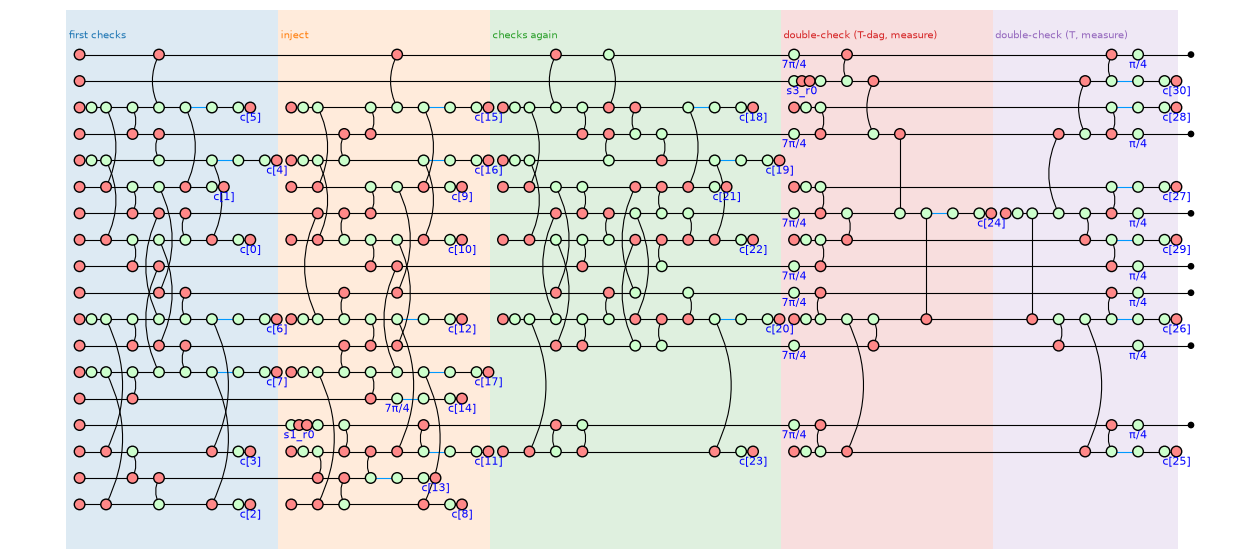

In [2]:
text = open('circuits/cultivation/d3_cultivation.stim').read()
names = ['first checks', 'inject', 'checks again', 'double-check (T-dag, measure)', 'double-check (T, measure)']
real, circ = program_from_stim(text, names=names)
print(real.qubits, "qubits; gates:", dict(Counter(g.name for st in real.stages for g in st.circuit.gates)))
draw_program(real, 0, show_time=False, labels=False, figsize=(16, 7))

What a run that passes should hold: `code_at` reads it from the diagram. It is the 7-qubit colour code, holding a state that is not a stabilizer state (the T state).

In [3]:
colour_code = real.code_at(real.num_stages - 1)
print(colour_code)

[[7, 1, 3]] CSS code on qubits 0, 3, 6, 8, 9, 11, 14 (holding a non-Clifford logical state)
    stabilizer (-1)^(c[4])XIIXXXI
    stabilizer (-1)^(c[27])IIXIXXX
    stabilizer (-1)^(c[28] + c[5])IXIXXIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII


## 2. What other tools give

`circuit_distance` asks Stim for the fewest faults. Stim refuses the real circuit, because of its T gates:

In [4]:
try:
    circuit_distance(real)
except NotCliffordError as e:
    print("NotCliffordError:", e)

NotCliffordError: stage 1: T*(13) is not a Clifford gate this function supports


The published circuit files put S in place of T, so that Stim can run them. For that circuit Stim finds 3 (`code_out` is the code to protect; with S the end state is a stabilizer state, so `code_at` alone sees no logical qubit in it):

In [5]:
with_s = program_from_stim(text.replace('T_DAG ', 'S_DAG ').replace('\nT ', '\nS '), names=names)[0]
print(circuit_distance(with_s, code_out=colour_code.data()))

full circuit distance of stages 0-4: 3 (- -> Y: 3)


But that is a different circuit. For the real one, the question is open.

## 3. The idea, on a small circuit

Five qubits: an encoder puts qubit 0 into the three-qubit **phase-flip code** (checks $X_0X_1$ and $X_1X_2$), then two rounds of these checks. Round 1 writes `c`, round 2 writes `d`. The encoder is perfect here: errors only in the rounds (`stages=[1, 2]`).

**Function:** `error_formulas`. After every gate it puts two switches on each qubit, `xk` and `zk` (the error $X^{x}Z^{z}$), and pushes them to the end with the ZX rules for Paulis (a Hadamard swaps X and Z, a CNOT copies X forward and Z backward). Each result then flips when a sum of switches is odd.

In [6]:
HEADER = 'OPENQASM 2.0;\ninclude "qelib1.inc";\nqreg q[5];\ncreg c[2];\ncreg d[2];\n'
ENCODE = 'cx q[0], q[1]; cx q[0], q[2]; h q[0]; h q[1]; h q[2];\n'
ROUND = '''h q[3]; h q[4];
cx q[3], q[0]; cx q[3], q[1]; cx q[4], q[1]; cx q[4], q[2];
h q[3]; h q[4];
measure q[3] -> c[0]; measure q[4] -> c[1];
'''
ROUND_2 = 'reset q[3]; reset q[4];\n' + ROUND.replace('c[', 'd[')
small = QProgram(5, bits=4, initial_states={1: '0', 2: '0', 3: '0', 4: '0'})
for stage, part in [('encode', ENCODE), ('round 1', ROUND), ('round 2', ROUND_2)]:
    small.add_circuit(Circuit.from_qasm(HEADER + part), name=stage)
ef = error_formulas(small, stages=[1, 2])
print(len(ef.places), "places,", 2 * len(ef.places), "switches")
for c in sorted(ef.flips):
    print("  {} flips when  {}  is odd".format(c, ef.formula(c)))

26 places, 52 switches
  c[0] flips when  z0 + z2 + z4 + x10  is odd
  c[1] flips when  z1 + z5 + z6 + z8 + x11  is odd
  d[0] flips when  z3 + z5 + z7 + x12 + z14 + z16 + z18 + x24  is odd
  d[1] flips when  z5 + z7 + z9 + x13 + z15 + z19 + z20 + z22 + x25  is odd


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


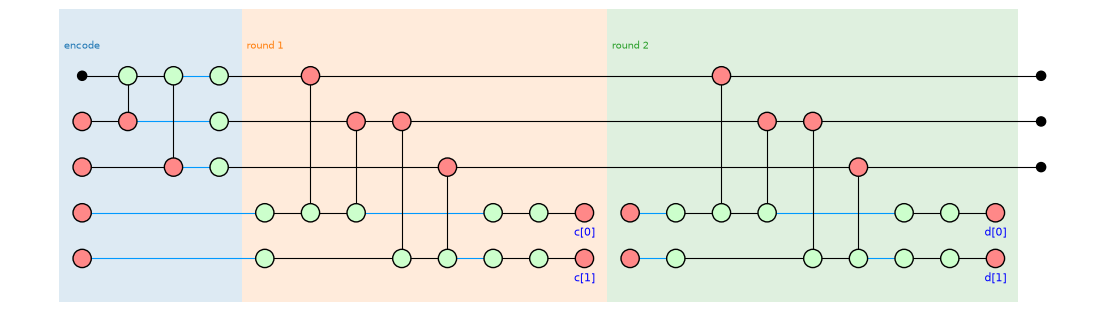

In [7]:
draw_program(small, 0, time_axis=False, show_time=False, even_rows=True, labels_above=True, figsize=(14, 3.8))

Without errors every result is 0, so each result is a **check**. A pattern of errors is *caught* (a check fires), *harmless* (the checks pass and the output is right) or *wrong* (the checks pass and the encoded qubit is changed). An error between the rounds, on data qubit 1:

In [8]:
k = max(pl.index for pl in ef.places if pl.stage == 1 and pl.qubit == 1)
for letter in 'XZ':
    flipped, _t, out = ef.signature({k: letter})
    print("{}: flips {}, leaves {} on the output -> {}".format(letter, sorted(flipped) or 'nothing', sorted(out),
                                                             ef.classify({k: letter})))
rows = ef.single_errors()
print("\nall single errors:", Counter((letter, verdict) for _p, letter, verdict, _f in rows))

X: flips nothing, leaves ['ox1'] on the output -> wrong
Z: flips ['d[0]', 'd[1]'], leaves ['oz1'] on the output -> caught

all single errors: Counter({('Y', 'caught'): 26, ('Z', 'caught'): 20, ('X', 'wrong'): 12, ('X', 'harmless'): 8, ('X', 'caught'): 6, ('Z', 'harmless'): 6})


Z is seen, X is not: these checks measure $X_0X_1$ and $X_1X_2$, and X on one data qubit changes the encoded qubit. The formulas say this without simulating any state.

## 4. Every error of cultivation in one diagram

The same function on the real circuit: 304 places, 608 switches.

The T gates need one more step, and this is where zxqec does what a Clifford tool cannot. An X error that reaches a T gate passes through it, but leaves an $S^\dagger$ behind ($TX = XT^\dagger$ up to a phase, and $T^\dagger = S^\dagger T$). That $S^\dagger$ is not a Pauli error, so it cannot be pushed on like one. `error_formulas` gives each such T gate one more switch, `f`, puts an $S^\dagger$ that `f` turns on after the gate, and simplifies this one circuit with `reduce_gpf`.

**Why `reduce_gpf`:** it keeps Boolean values (the results, the switches) as phases of the diagram and T gates as phase gadgets. So one simplification holds every value of every switch at once.

In [9]:
t0 = time.time()
ef = error_formulas(real)
print("switches pushed and the diagram simplified once: {:.1f} s".format(time.time() - t0))
print(len(ef.places), "places,", 2 * len(ef.places), "switches;", len(ef.t_flips), "T gates that an X error can reach")
whole, reduced = real.quantum_graph(), ef.reduced.to_graph()
print("spiders: the circuit {}, with every error and simplified {}".format(
    sum(1 for v in whole.vertices() if whole.type(v) != 0), sum(1 for v in reduced.vertices() if reduced.type(v) != 0)))

switches pushed and the diagram simplified once: 0.3 s
304 places, 608 switches; 15 T gates that an X error can reach
spiders: the circuit 370, with every error and simplified 43


The simplified diagram has one phase gadget per T gate (`phase_polynomial` lists them). Each gadget puts a phase on a parity of bits; its angle is an odd multiple of $\pi/4$, so it holds a T. The hub of gadget $i$ has the phase $\pi(f_i + \dots)$. When that is $\pi$, the angle changes sign, and **the T in it becomes a $T^\dagger$**. So the error that no Clifford tool can push is, in the diagram, the sign of one phase.

In [10]:
g = ef.reduced.to_graph()
_poly, gadgets = phase_polynomial(g)
for hub, leaves in gadgets:
    print("angle {:>4} pi   hub phase: pi ({})".format(str(g.phase(leaves[0])), g.phase(hub)))

angle  7/4 pi   hub phase: pi (f0 + ox8 + ox14 + ox11)
angle  7/4 pi   hub phase: pi (f1 + ox9 + ox11 + ox8)
angle  7/4 pi   hub phase: pi (f2 + ox8 + ox14 + ox9)
angle  7/4 pi   hub phase: pi (f3 + ox14 + ox9 + ox11)
angle  7/4 pi   hub phase: pi (f4 + ox8)
angle  7/4 pi   hub phase: pi (f5 + ox9)
angle  7/4 pi   hub phase: pi (f6 + ox11)
angle  7/4 pi   hub phase: pi (f7 + ox14)
angle  5/4 pi   hub phase: pi (f8 + ox9 + ox11 + ox8)
angle  5/4 pi   hub phase: pi (f9 + ox8 + ox14 + ox9)
angle  5/4 pi   hub phase: pi (f10 + ox14 + ox9 + ox11)
angle  5/4 pi   hub phase: pi (f11 + ox8)
angle  5/4 pi   hub phase: pi (f12 + ox9)
angle  5/4 pi   hub phase: pi (f13 + ox11)
angle  5/4 pi   hub phase: pi (f14 + ox14)


(`ox q` is an X error left on output qubit `q`: it also passes the T gates of the double-check.)

The same diagram as a picture, for the run where every result is 0 and with no error left on the outputs, so that the only variables left are the 15 switches `f`. Left: the six green spiders of the Z-layer. Right, top: the seven outputs (the colour code). Right, below: the 15 gadgets, one per T gate: a red hub with phase $\pi f_i$ and a green leaf with the angle.

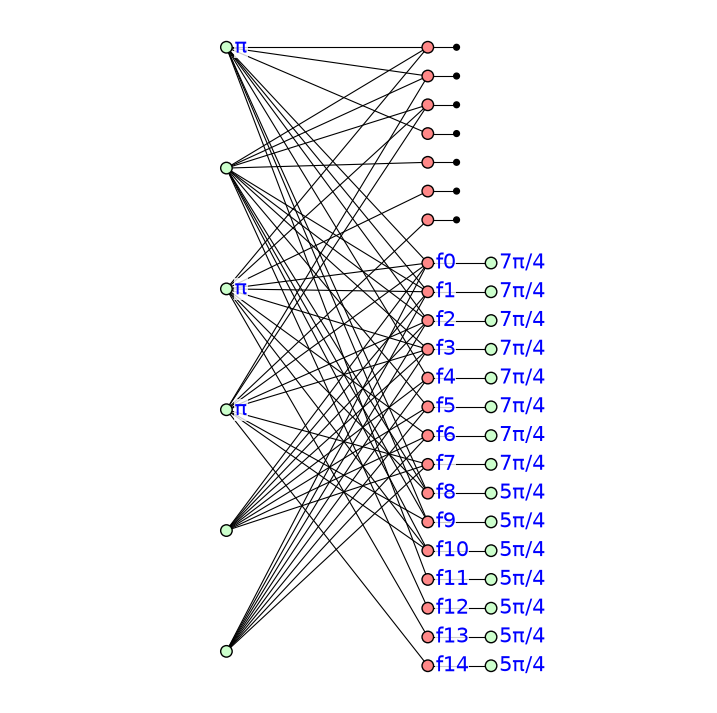

In [11]:
shown = g.substitute_variables({v: 0 for v in boolean_variables(g) if v in ef.flips or v[:2] in ('ox', 'oz')})
layout_gpf(shown, leaf_gap=2.2)
draw_graph(shown, time_axis=False, show_time=False, label_size=15, label_side='right', figsize=(9, 9))

## 5. The checks come from the diagram

`reduce_gpf` also finds the **checks**: sums of results that are 0 in every run without errors. Nobody has to write them down. `check_detectors` compares them with the DETECTOR lines the authors wrote in the file: they are the same 26 checks, up to adding lines together (each line is a sum of the tool's checks, and each check a sum of lines).

In [12]:
print(check_detectors(real, circ.detectors))
on_results = [(d, s) for d, s in ef.detector_switches() if {v.name for v in d.free_vars()} <= set(ef.flips)]
print("\nfor each check, the number of switches that flip it:")
print(', '.join("{}: {}".format(d, len(s)) for d, s in on_results))

26 declared detector(s): 26 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 26 independent detectors on its results, all sums of declared ones

for each check, the number of switches that flip it:
c[9]: 8, c[1]: 8, c[0]: 8, c[2]: 8, c[10]: 8, c[8]: 8, c[3]: 8, c[15] + c[5]: 32, c[16] + c[4]: 29, c[17] + c[7]: 26, c[13] + c[12] + c[6]: 31, c[12] + c[6]: 31, c[11]: 8, c[18] + c[5]: 41, c[21]: 60, c[23]: 70, c[20] + c[12]: 36, c[22]: 69, c[19] + c[4]: 43, c[30]: 8, c[29]: 8, c[26]: 14, c[28]: 11, c[25]: 8, c[14] + c[24] + c[4] + c[5] + c[6] + c[7]: 127, c[14] + c[27] + c[4] + c[5] + c[6] + c[7]: 135


(Two more facts come out of `reduce_gpf`: a reset of qubits 1 and 14 throws away a 0, written `s1_r0` and `s3_r0`. Nobody reads these values, so they are not checks.)

## 6. The fault distance

**Single faults.** `single_errors` decides X, Y and Z at every place:

In [13]:
rows = ef.single_errors()
by_gate = Counter((place.name, verdict) for place, _letter, verdict, _fired in rows)
print("after     caught  harmless  wrong")
for gate in sorted({place.name for place in ef.places}):
    print("{:8s}  {:5d}   {:5d}    {:5d}".format(gate, *(by_gate[gate, v] for v in ('caught', 'harmless', 'wrong'))))

after     caught  harmless  wrong
CNOT        591      33        0
HAD          82      41        0
Reset        74      46        0
T            44       1        0


No single fault is wrong. **Pairs.** `lowest_wrong` tries every single fault, then every pair of faults at two gates. A fault after a CNOT can hit both of its qubits (15 kinds), as in the usual noise model. A pair only adds two sets of switches, so most pairs are decided from the formulas alone; the rest from one small simplification each.

In [14]:
t0 = time.time()
weight, wrong = ef.lowest_wrong(max_weight=2)
print("fault distance: {}   wrong pairs: {}   time: {:.0f} s".format(weight, len(wrong), time.time() - t0))
for pattern in wrong[:4]:
    print("  ", ef.describe(pattern))

fault distance: 2   wrong pairs: 48   time: 238 s
   X on qubit 3 after the CNOT (stage 3, gate 25); Y on qubit 8 after the CNOT (stage 4, gate 11)
   X on qubit 3 after the CNOT (stage 3, gate 25); X on qubit 7, Y on qubit 8 after the CNOT (stage 4, gate 11)
   X on qubit 3 after the CNOT (stage 3, gate 25); X on qubit 8 after the T (stage 4, gate 17)
   X on qubit 3 after the CNOT (stage 3, gate 25); Y on qubit 8 after the T (stage 4, gate 17)


For comparison, the slow way (`classify_directly`: put the errors into the circuit and simplify the whole circuit), timed on a few pairs:

In [15]:
t0 = time.time()
for pattern in wrong[:10]:
    ef.classify_directly(pattern)
per = (time.time() - t0) / 10
print("{:.2f} s per pair, so all 1,695,420 pairs would take about {:.0f} hours".format(per, per * 1695420 / 3600))

0.12 s per pair, so all 1,695,420 pairs would take about 55 hours


## 7. Why 2: the T gate

Every wrong pair has an X error that reaches a T gate (`signature` lists the T gates a pattern flips):

In [16]:
flipped = [ef.signature(pattern)[1] for pattern in wrong]
print("every wrong pair flips a T gate:", all(flipped))
print("in stage:", sorted({t.stage for t in ef.t_flips if any(t.name in f for f in flipped)}))

every wrong pair flips a T gate: True
in stage: [4]


The same 48 pairs on the circuit with S in place of T (its places are the same):

In [17]:
ef_s = error_formulas(with_s, code_out=colour_code)
assert [(p.stage, p.gate, p.qubit) for p in ef_s.places] == [(p.stage, p.gate, p.qubit) for p in ef.places]
print("the 48 pairs with S:", Counter(ef_s.classify(pattern) for pattern in wrong))
t0 = time.time()
print("with S, the fewest wrong faults (trying up to 2):", ef_s.lowest_wrong(max_weight=2), "{:.0f} s".format(time.time() - t0))

the 48 pairs with S: Counter({'caught': 36, 'harmless': 12})


with S, the fewest wrong faults (trying up to 2): (None, []) 72 s


With S every one of them is caught or harmless, and no pair is wrong (Stim's 3, from section 2, agrees). So the T gate is the whole reason. The X error leaves an $S^\dagger$ behind it, a Clifford error that the double-check in stage 4 does not fully see. Chan et al. give the same reason.

## 8. How often is a kept state wrong?

`sample(p, shots)`: after each gate, a fault with probability `p`. A draw adds up switches and looks up the verdict of its pattern; when its faults reach a T gate, how the run ends is drawn from the shares that `outcomes` gives (a T error can be caught in some runs and not in others). 20,000 runs take seconds:

In [18]:
print("     p    thrown away   kept   wrong among kept")
for prob in (0.001, 0.003, 0.01):
    n = ef.sample(prob, 20000, seed=1)
    kept = n['harmless'] + n['wrong']
    print("{:7.3f}    {:5.1f} %     {:6d}   {}".format(prob, 100 * n['caught'] / 20000, kept, n['wrong']))

     p    thrown away   kept   wrong among kept


  0.001     15.0 %      16993   0


  0.003     38.8 %      12248   0


  0.010     80.5 %       3898   0


`p` can differ per gate (a map from gate name to `p`):

In [19]:
print(ef.sample({'CNOT': 0.003, 'HAD': 0.001, 'T': 0.002, 'Reset': 0.003}, 20000, seed=2))

{'caught': 6975, 'harmless': 13025, 'wrong': 0}


## 9. Can we trust it?

Every single error and every wrong pair, the slow way:

In [20]:
singles = [{pl.index: letter} for pl in ef.places for letter in 'XYZ']
t0 = time.time()
agree = [ef.classify(e) == ef.classify_directly(e) for e in singles + wrong]
print(sum(agree), "of", len(agree), "agree; {:.0f} s".format(time.time() - t0))

960 of 960 agree; 63 s


## What this shows

| question | answer | function |
|---|---|---|
| can Stim answer for real T? | no, it needs S in place of T | `circuit_distance` |
| the checks | 26, found from the diagram; the file's checks, up to adding lines together | `reduce_gpf`, `check_detectors` |
| every error at once | one diagram, simplified once in a fraction of a second; each T error is the sign of one phase | `error_formulas`, `phase_polynomial` |
| fault distance with real T | **2** (48 pairs, in minutes instead of days) | `lowest_wrong` |
| why | each pair puts an X error on a T gate; with S all 48 are caught or harmless | `signature`, `classify` |
| how often | estimated from random faults, without simulating a state | `sample` |
| trust | 960 of 960 verdicts agree with the slow way | `classify_directly` |

**What only zxqec does here.**

1. **Errors as Boolean switches inside the ZX-diagram.** Every possible error is in one diagram, so its effect on every result is a short formula.
2. **Non-Clifford errors.** An X error on a T gate becomes the sign of one phase gadget. A Clifford simulator cannot hold this error; here it is one more Boolean switch.
3. **One simplification, with the results kept as variables** (`reduce_gpf`). It also finds the checks itself and reads the code the output is in (`code_at`), so the circuit file needs no DETECTOR lines and no stated logical operator.

## Appendix: the idea we started from, and what the code does

| the idea | here |
|---|---|
| an error after every gate | yes, on each qubit of the gate (`stages=` picks the stages); not after a measurement: in d = 3 the qubit is reset next or never used again |
| $2g$ Boolean variables | 2 per qubit per gate: a CNOT has 4; d = 3 has 608 |
| noise $pX + (1-p)I$ | X, Y or Z, $p/3$ each, after a one-qubit gate; the 15 Paulis, $p/15$ each, after a CNOT; `p` can depend on the gate |
| what each detector gets | `detector_switches`, `formula` |
| which errors give a logical error | `single_errors`, `classify` |
| the least number of errors | `lowest_wrong`: all 1,848 single faults, then all 1.7 million pairs |
| a SAT problem at the end | not done: there are about a billion triples, too many to try; for errors that reach no T gate the formulas are sums (XOR), ready for a SAT or integer-program solver |
| getting the formulas is efficient | yes: pushing the switches is fast; one `reduce_gpf`, with only the 15 `f` switches |
| symbolic rewriting, not simulation | yes: no quantum state is computed |
| two rounds, an error in between | section 3 |